# E2 Augmentations de données (contrôle visuel)

**L'essentiel** : chaque augmentation garde le masque aligné sur la racine et produit des images réalistes. L'occlusion (section 5), essayée ensuite (notebook 06), n'a rien apporté : elle n'est pas utilisée.

Ce que le modèle reçoit à l'entraînement : des carrés de 256 x 256 pris dans les images **prétraitées** et réduites de moitié, puis augmentés à la volée (`augment` dans `src/prmi/dataset.py`). Masques corrigés en aplat bleu.

| Augmentation | Probabilité | Plage | Touche le masque |
|---|---|---|---|
| Orientation (miroir, quarts de tour : 8 possibilités) | toujours | une des 8 au hasard | oui, la même |
| Gamma (< 1 éclaircit, > 1 assombrit) | 0,5 | 0,7 à 1,4 | non |
| Surexposition (ajout d'une constante) | 0,25 | 0 à 0,25 | non |
| Bruit gaussien (écart-type) | 0,25 | 0,01 à 0,05 | non |
| Flou gaussien (sigma, en pixels) | 0,25 | 0,5 à 1,2 | non |
| Occlusion (option `occlusion` de `RootCrops`) : 1 ou 2 morceaux de sol sur l'axe d'une racine | non utilisée (essai du notebook 06) | ellipses de demi-axes 0,6 à 1,5 fois le diamètre local de la racine (au moins 4 à 8 px, au plus 30 px) | non, la racine continue sous la terre |

Appliquées dans cet ordre, puis l'image est ramenée entre 0 et 1. Un carré sur cinq environ (0,5 x 0,75³ = 21 %) ne reçoit aucune augmentation de couleur.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import matplotlib.pyplot as plt
import numpy as np

from prmi import dataset as ds, viz
from prmi.dataset import CROP, RootCrops, load_lot, to_display
from prmi.diagnostic import overlay_mask

viz.apply_style()
%config InlineBackend.figure_formats = ['jpeg']
plt.rcParams['figure.dpi'] = 90

OVERLAY = True    # False : images seules, pour mieux voir l'effet sous les racines
TYPES = ['typique', 'sombre', 'faible contraste', 'saturée']


def show(image, mask):
    img = (np.clip(image, 0, 1) * 255).astype(np.uint8)
    return overlay_mask(img, mask) if OVERLAY else img


def crop_on_root(it):
    """Carré de CROP pixels centré sur le pixel de racine médian de l'image, repoussé dans l'image."""
    ys, xs = np.nonzero(it['mask'])
    h, w = it['mask'].shape
    y0 = np.clip(int(np.median(ys)) - CROP // 2, 0, h - CROP)
    x0 = np.clip(int(np.median(xs)) - CROP // 2, 0, w - CROP)
    return it['image'][y0:y0 + CROP, x0:x0 + CROP], it['mask'][y0:y0 + CROP, x0:x0 + CROP]

In [2]:
train_items = load_lot('train', 2)
examples = [next(it for it in train_items if it['type'] == t and it['mask'].mean() > 0.02) for t in TYPES]
crops = [crop_on_root(it) for it in examples]
for t, it in zip(TYPES, examples):
    print(f'{t:17s} {it["name"]}')

typique           Peanut_T014_L028_2015.05.28_130114_BAZ_DPI150
sombre            Peanut_T004_L054_2015.07.22_111917_BAZ_DPI150
faible contraste  Peanut_T020_L085_2015.07.06_110901_BAZ_DPI150
saturée           Peanut_T005_L066_2015.06.11_123515_BAZ_DPI150


## 1. Les 8 orientations

Image et masque tournent ensemble : l'aplat doit rester exactement sur la racine.

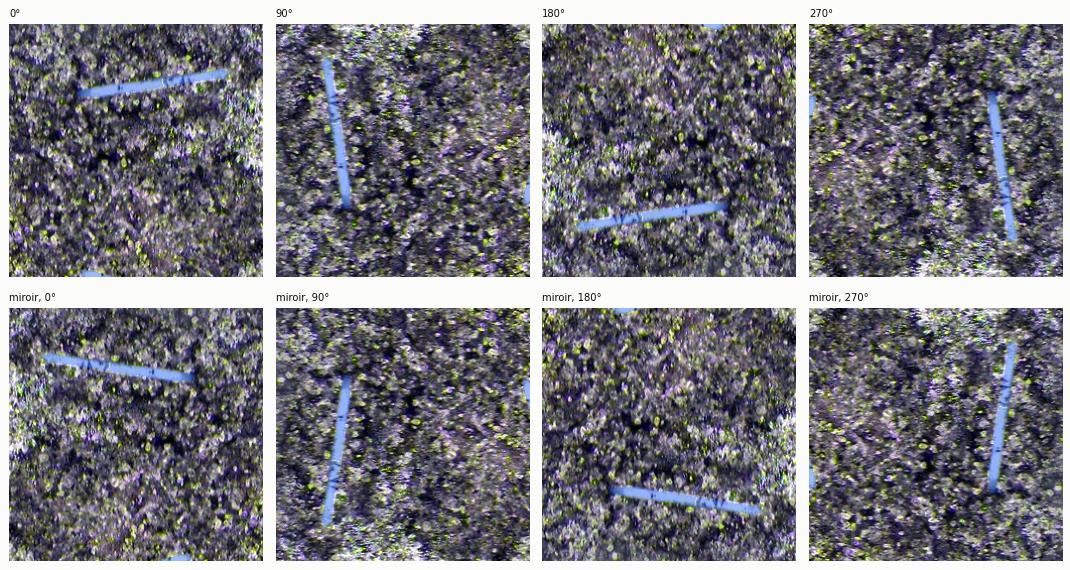

In [3]:
image, mask = crops[0]
pairs = [ds.orient(image, mask, flip, k) for flip in (False, True) for k in range(4)]
titles = [f'{"miroir, " if flip else ""}{90 * k}°' for flip in (False, True) for k in range(4)]
viz.image_grid([show(*p) for p in pairs], titles, ncols=4);

## 2. Chaque augmentation de couleur, à ses valeurs extrêmes

Une ligne par type d'image. Le masque n'est jamais modifié : seule l'image change.

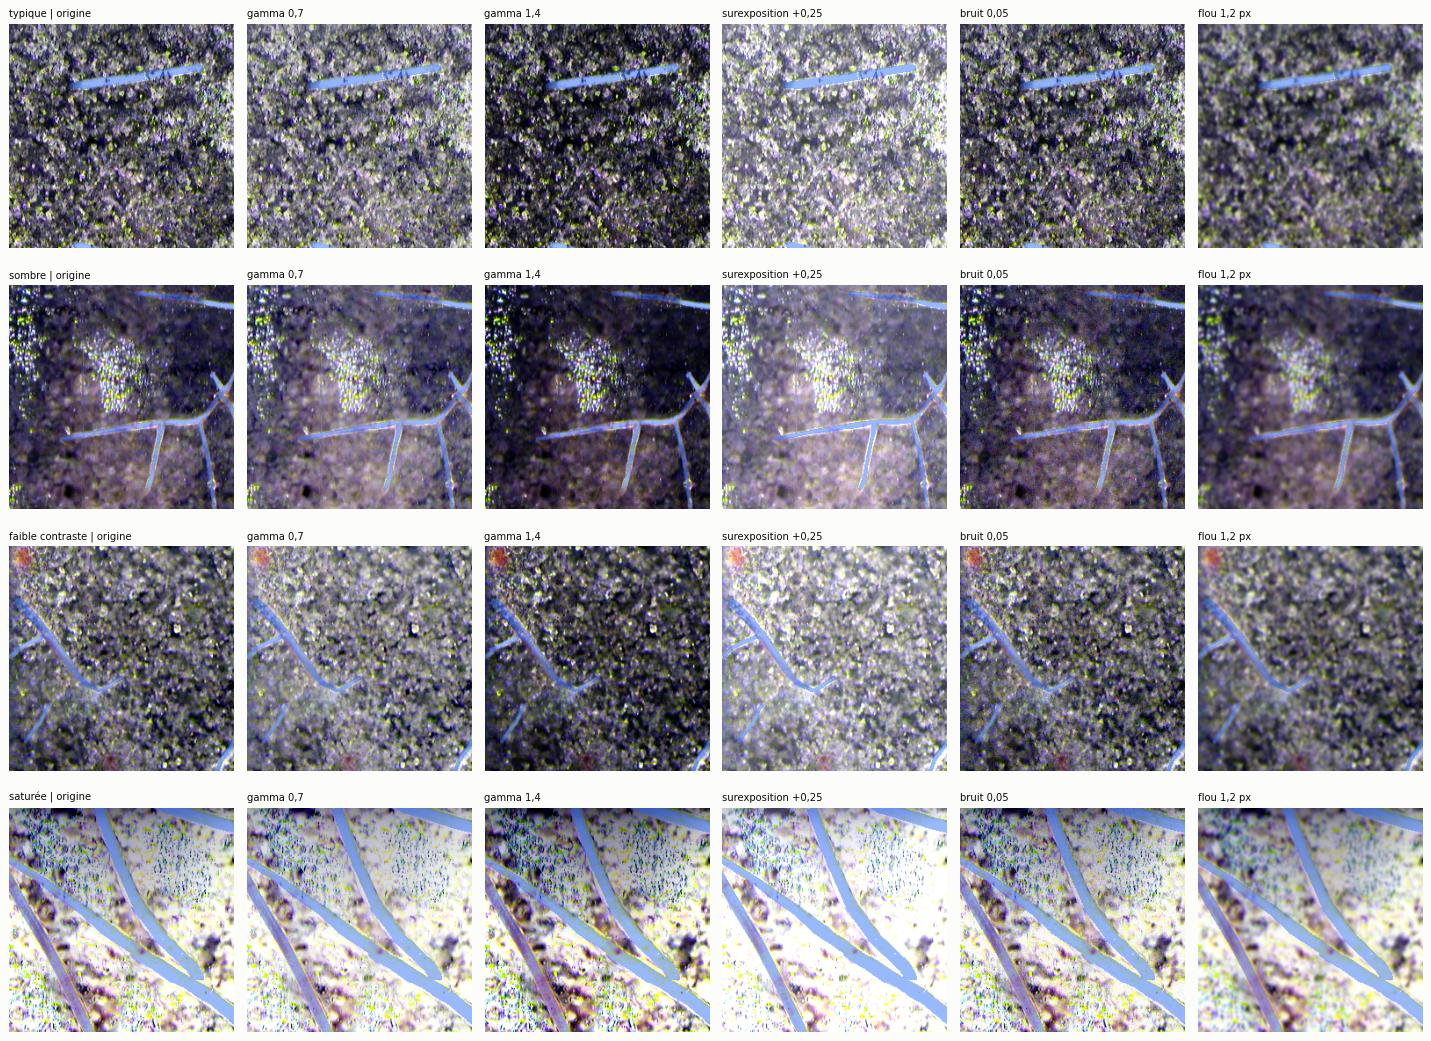

In [4]:
rng = np.random.default_rng(0)
variants = [('origine', lambda x: x),
            ('gamma 0,7', lambda x: ds.gamma(x, 0.7)), ('gamma 1,4', lambda x: ds.gamma(x, 1.4)),
            ('surexposition +0,25', lambda x: ds.overexpose(x, 0.25)),
            ('bruit 0,05', lambda x: ds.add_noise(x, 0.05, rng)), ('flou 1,2 px', lambda x: ds.blur(x, 1.2))]
images, titles = [], []
for t, (image, mask) in zip(TYPES, crops):
    for label, f in variants:
        images.append(show(f(image), mask))
        titles.append(f'{t} | {label}' if label == 'origine' else label)
viz.image_grid(images, titles, ncols=len(variants), width=16);

## 3. Tirages au hasard sur un même carré

Ce que le modèle peut voir d'un même morceau de racine d'une époque à l'autre.

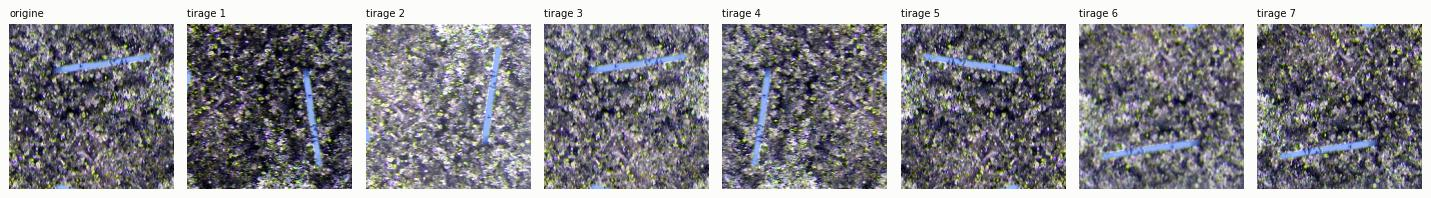

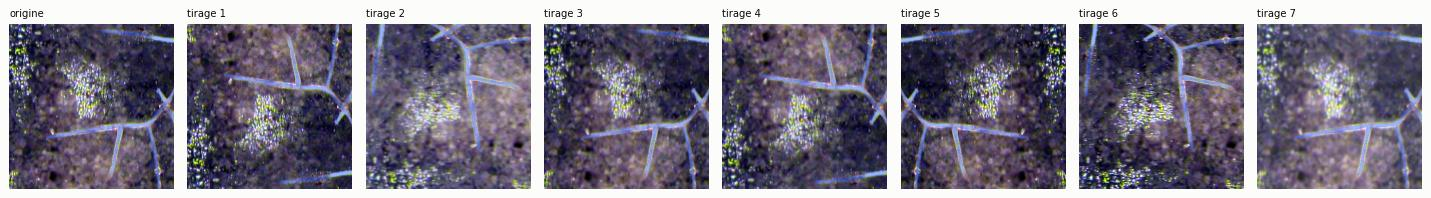

In [5]:
rng = np.random.default_rng(1)
for image, mask in crops[:2]:
    draws = [(image, mask)] + [ds.augment(image, mask, rng) for _ in range(7)]
    viz.image_grid([show(*d) for d in draws], ['origine'] + [f'tirage {i}' for i in range(1, 8)], ncols=8, width=16)

## 4. Carrés tels que le modèle les reçoit

Tirage complet de l'entraînement (`RootCrops`, augmentation comprise) : position du carré, orientation et couleur au hasard. Les carrés sans racine sont normaux (images vides, ou carré tiré loin des racines).

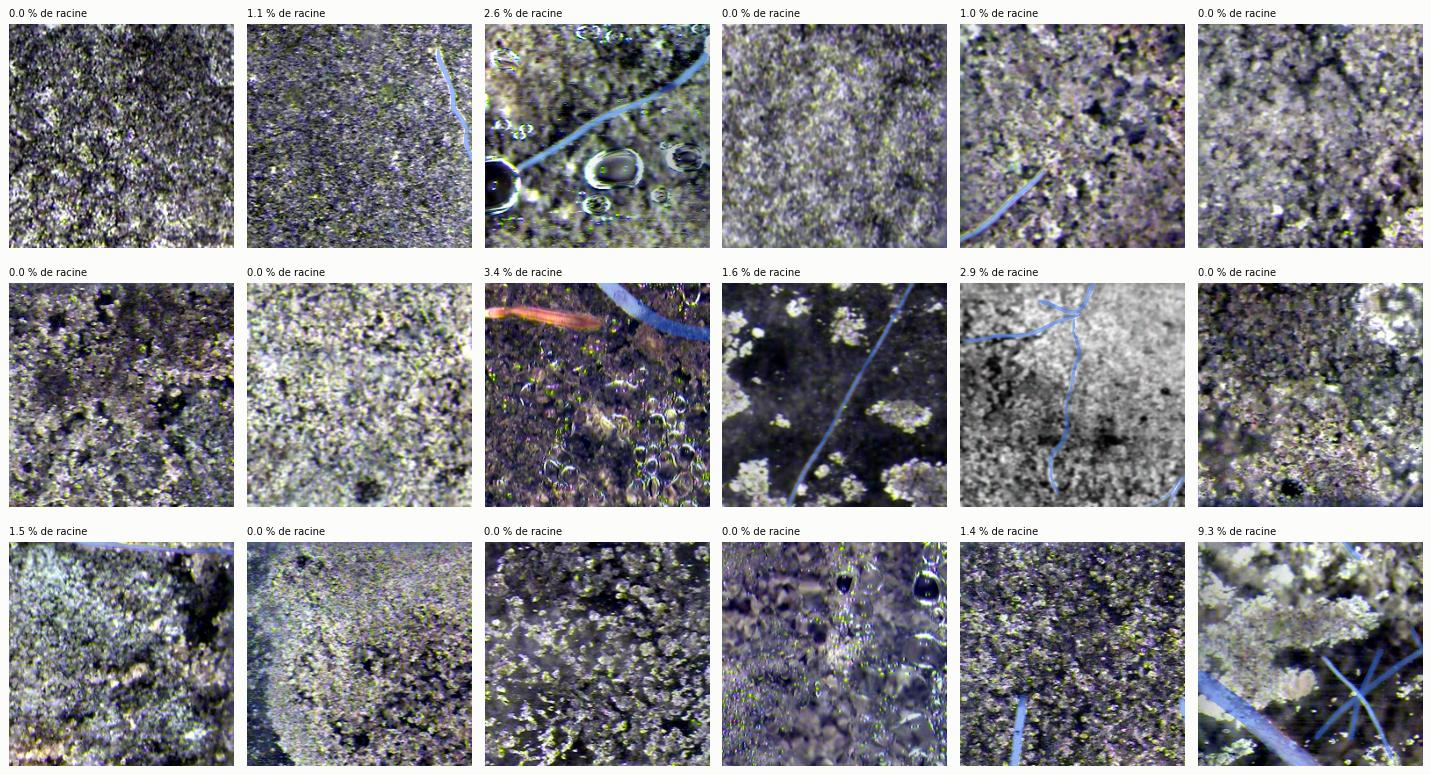

In [6]:
crops_aug = RootCrops(train_items, seed=1, augment=True)
pairs = [crops_aug[i] for i in range(0, 360, 20)]
images = [show(to_display(x) / 255, y[0].numpy() > 0) for x, y in pairs]
viz.image_grid(images, [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs], ncols=6, width=16);

## 5. Occlusion par la terre

But : apprendre au modèle à deviner une racine cachée par la terre ou une goutte. Un morceau de sol est pris **dans la même image**, à un endroit sans racine (même éclairage), puis collé sur l'axe d'une racine, en ellipse d'orientation aléatoire, avec un bord adouci. **La taille suit le diamètre de la racine à cet endroit** : chaque demi-axe est tiré entre 0,6 et 1,5 fois le diamètre (au moins 4 à 8 px pour les racines fines, au plus 30 px), pour que la tache couvre toute la largeur d'une grosse racine sans cacher de longs tronçons de racine fine. **Le masque ne change pas** : la racine continue sous la terre.

Une dernière ligne montre la racine la plus grosse du lot, centrée sur son point le plus large (diamètre indiqué). Pour chaque carré : l'original, trois occlusions tirées au hasard (images seules, pour voir si la racine disparaît vraiment), puis la dernière avec le masque en aplat bleu et le sol collé en rouge.

grosse racine : Peanut_T013_L021_2016.06.27_125213_BAZ_DPI150, diamètre max 50 px (demi-résolution)


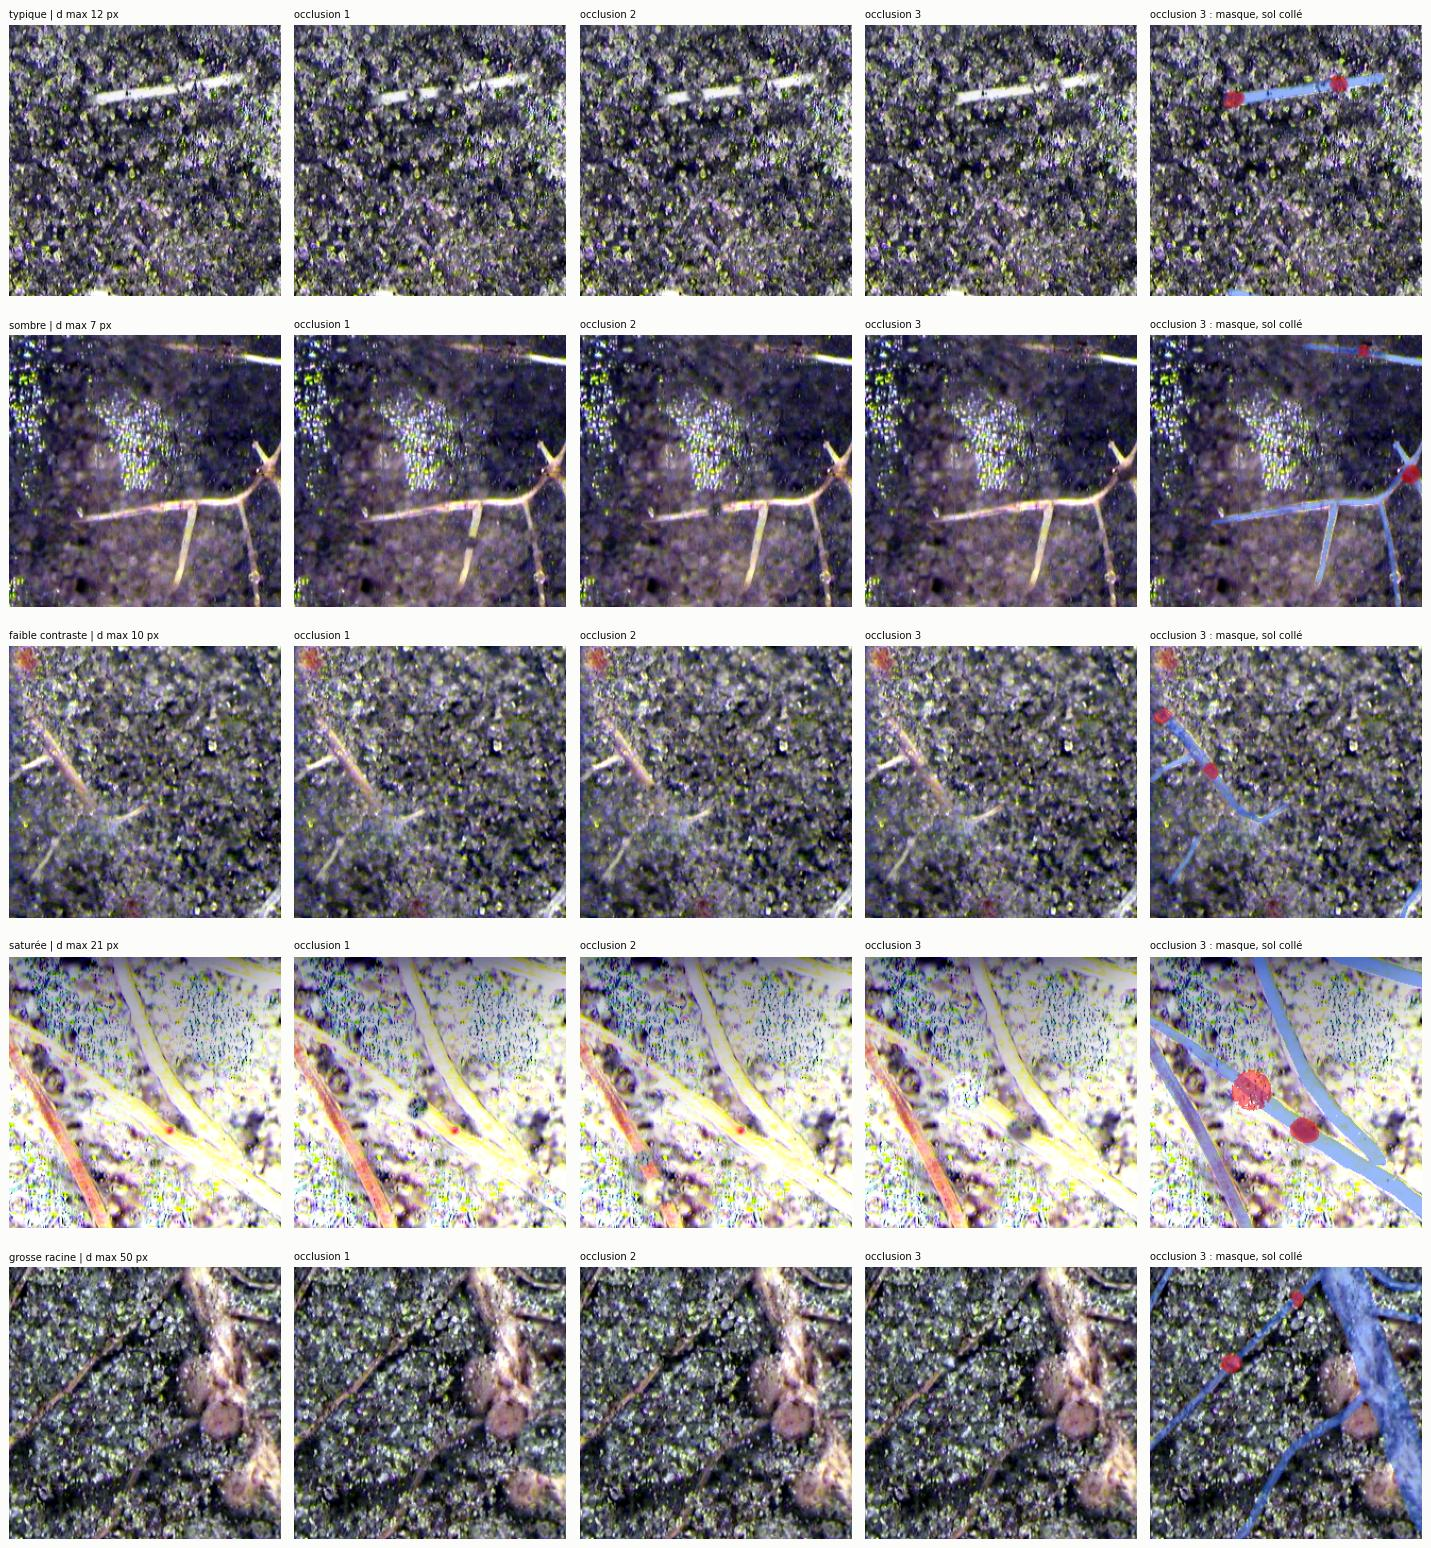

In [7]:
from scipy import ndimage as ndi

dists = [ndi.distance_transform_edt(it['mask']) for it in train_items]
k = int(np.argmax([d.max() for d in dists]))
thick = train_items[k]
y, x = np.unravel_index(dists[k].argmax(), dists[k].shape)
h, w = thick['mask'].shape
y0, x0 = np.clip(y - CROP // 2, 0, h - CROP), np.clip(x - CROP // 2, 0, w - CROP)
thick_crop = thick['image'][y0:y0 + CROP, x0:x0 + CROP], thick['mask'][y0:y0 + CROP, x0:x0 + CROP]
print(f"grosse racine : {thick['name']}, diamètre max {2 * dists[k].max() - 1:.0f} px (demi-résolution)")

rng = np.random.default_rng(2)
plain = lambda x: (np.clip(x, 0, 1) * 255).astype(np.uint8)
images, titles = [], []
for t, it, (image, mask) in zip(TYPES + ['grosse racine'], examples + [thick], crops + [thick_crop]):
    draws = [ds.occlude(ds.occlude(image, mask, it['image'], it['mask'], rng), mask, it['image'], it['mask'], rng)
             for _ in range(3)]
    d = 2 * ndi.distance_transform_edt(mask).max() - 1
    pasted = np.abs(draws[-1] - image).max(-1) > 0.05      # zones collées, en rouge
    images += [plain(image)] + [plain(d_) for d_ in draws] + [overlay_mask(overlay_mask(plain(draws[-1]), mask), pasted,
                                                                          color=(255, 0, 0), alpha=0.5)]
    titles += [f'{t} | d max {d:.0f} px', 'occlusion 1', 'occlusion 2', 'occlusion 3', 'occlusion 3 : masque, sol collé']
viz.image_grid(images, titles, ncols=5, width=16);

Carrés tels que le modèle les recevrait avec l'occlusion activée sur tous les carrés avec racine (masque en aplat).

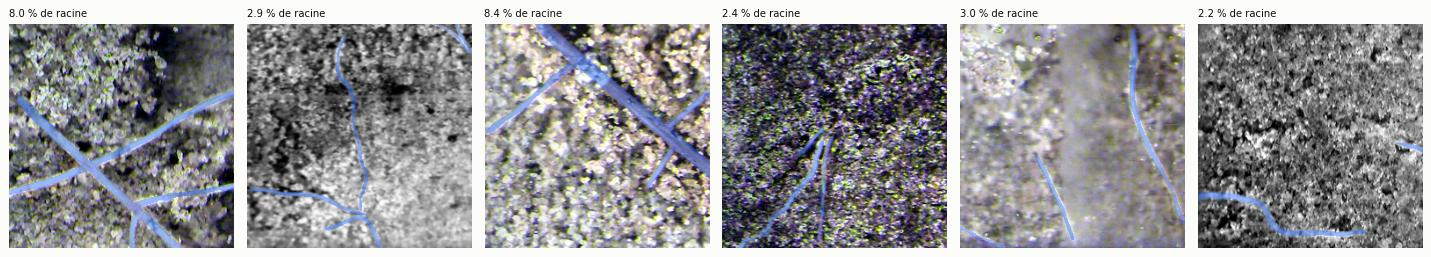

In [8]:
crops_occ = RootCrops(train_items, seed=4, augment=True, occlusion=1.0)
pairs = [crops_occ[i] for i in range(0, 600, 25) if crops_occ[i][1].mean() > 0.01][:12]
viz.image_grid([show(to_display(x) / 255, y[0].numpy() > 0) for x, y in pairs],
               [f'{y.mean() * 100:.1f} % de racine' for _, y in pairs], ncols=6, width=16);